# Function 5 - Week 5: observation review

Review what the completed experiments have shown before using a model to choose the next query. This notebook follows the Week 4 measured-output, progress and full-input-profile pattern.

The independent Week 5 `observations.csv` contains **20 initial observations and four returned queries**, including the Week 4 return received on **23 October 2026**. Larger signed outputs are better; all 4 input settings lie in `[0, 1)`. Earlier weekly notebooks retain the evidence and reasoning available at those times.


In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

week_dir = Path.cwd().resolve()
shared_dir = week_dir.parents[1] / "Shared"
if not (week_dir / "observation_review.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from its own Function_5/Week_05 folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from output_helpers import summarise_output_observations
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from observation_review_helpers import (
    plot_input_profiles,
    plot_output_review,
    plot_round_progress,
)

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Establish this week's evidence

Keep the supplied observations together as one initial batch. Their row order
does not describe a sequence of optimisation decisions. The four later rounds
each contain one deliberately selected query.

In [3]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ['x1', 'x2', 'x3', 'x4']
expected_columns = ["observation_id", "source_round", *input_columns, "y"]
if list(data.columns) != expected_columns:
    raise ValueError("Unexpected observation columns for Function 5.")
if data.isna().any().any() or not data["observation_id"].is_unique:
    raise ValueError("Observations need complete values and distinct IDs.")
if not np.isfinite(data[["source_round", *input_columns, "y"]].to_numpy()).all():
    raise ValueError("Inputs, outputs and rounds must be finite.")
if not ((data[input_columns] >= 0) & (data[input_columns] < 1)).all().all():
    raise ValueError("Input settings must lie in [0, 1).")
if data["source_round"].value_counts().to_dict() != {0: 20, 1: 1, 2: 1, 3: 1, 4: 1}:
    raise ValueError("This review expects the fixed Week 5 snapshot through round 4.")

initial = data.loc[data["source_round"].eq(0)]
returned = data.loc[data["source_round"].gt(0)].sort_values("source_round")
output_review = summarise_output_observations(data, input_columns=input_columns)
latest = data.loc[output_review["latest_mask"]].iloc[0]
earlier = data.loc[data["source_round"].lt(latest["source_round"])]
incumbent = data.loc[data["y"].idxmax()]

display(pd.DataFrame({
    "Evidence": ["Input dimensions", "Initial observations", "Returned queries",
                 "Total observations", "Queries available, including Week 5"],
    "Count": [len(input_columns), len(initial), len(returned), len(data),
              remaining_queries(week_dir)],
}))
print(f"Weekly queries used: {len(returned)}/{TOTAL_QUERY_WEEKS}")

,Evidence,Count
0,Input dimensions,4
1,Initial observations,20
2,Returned queries,4
3,Total observations,24
4,"Queries available, including Week 5",9


Weekly queries used: 4/13


## 2. Place the latest return among the observed outputs

The Week 4 return is **8449.98237455**, ranked **3/24 (1 = highest output)**. It does not improve the incumbent of **8662.40500125** (round-02).

In [4]:
print(output_review["report"])

Latest recorded submission: round 4 (1 new output).
Compared with 23 earlier observations (24 outputs in total).
Earlier output range: [0.112939795371, 8662.40500125].

round-04: y = 8449.98237455 (positive); rank 3/24 (1 = highest output).
Inputs: x1 = 0.999515, x2 = 0.989282, x3 = 0.999999, x4 = 0.999999
Within the earlier output range.


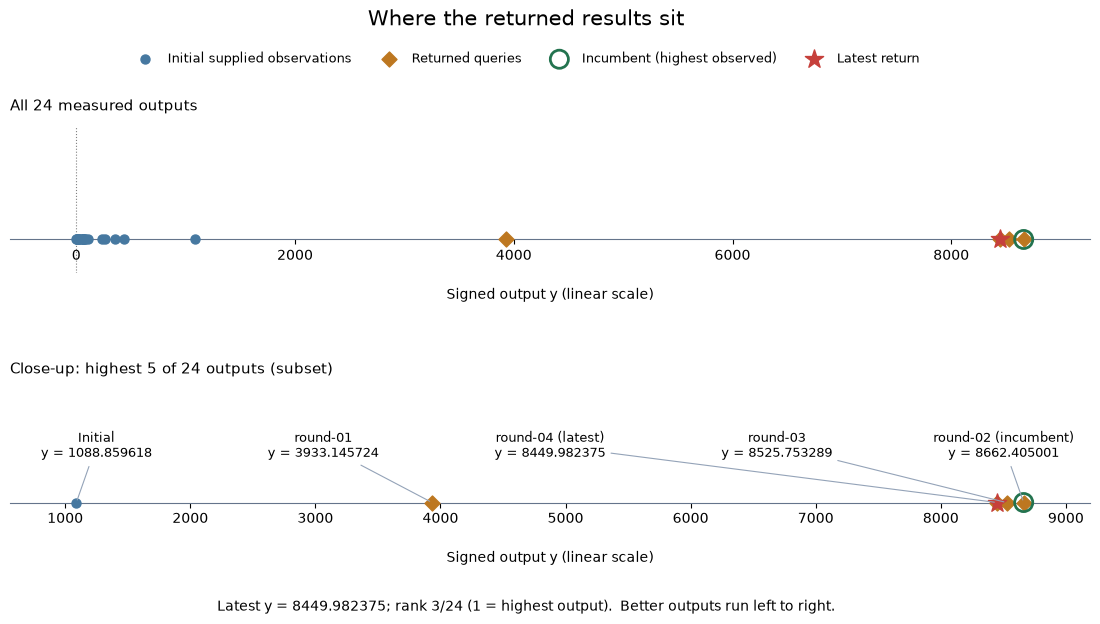

In [5]:
plot_output_review(
    output_review,
    save_to=figures / "observed-output-review.png",
)

Both panels use the original signed output: moving right means a better score.
The full-range panel retains all 24 observations; the labelled close-up separates
the five highest values. No observation is removed from the data or calculations.

These are the outputs at the locations sampled so far. The later queries were
chosen using earlier evidence, so this view does not estimate the distribution
of scores throughout the input domain or establish the unknown global maximum.

## 3. Track progress across completed rounds

A high rank describes one result's position. A chronological view answers a
different question: which experiments actually improved the best score seen?
Compare each return with the best available **before that round**, in the
function's original output units.

In [6]:
running_best = float(initial["y"].max())
progress_rows = [{
    "source_round": 0, "stage": "Initial batch", "returned_y": np.nan,
    "best_y": running_best, "change_vs_prior_best": np.nan,
}]
for _, observation in returned.iterrows():
    value = float(observation["y"])
    change = value - running_best
    running_best = max(running_best, value)
    progress_rows.append({
        "source_round": int(observation["source_round"]),
        "stage": f"Round {int(observation['source_round'])}",
        "returned_y": value, "best_y": running_best,
        "change_vs_prior_best": change,
    })
progress = pd.DataFrame(progress_rows)
display(progress.set_index("stage")[[
    "returned_y", "best_y", "change_vs_prior_best",
]].rename(columns={
    "returned_y": "Returned output", "best_y": "Best observed after stage",
    "change_vs_prior_best": "Return minus previous best",
}).style.format(precision=6, na_rep="—"))

,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,—,1088.859618,—
Round 1,3933.145724,3933.145724,2844.286106
Round 2,8662.405001,8662.405001,4729.259277
Round 3,8525.753289,8662.405001,-136.651712
Round 4,8449.982375,8662.405001,-212.422627


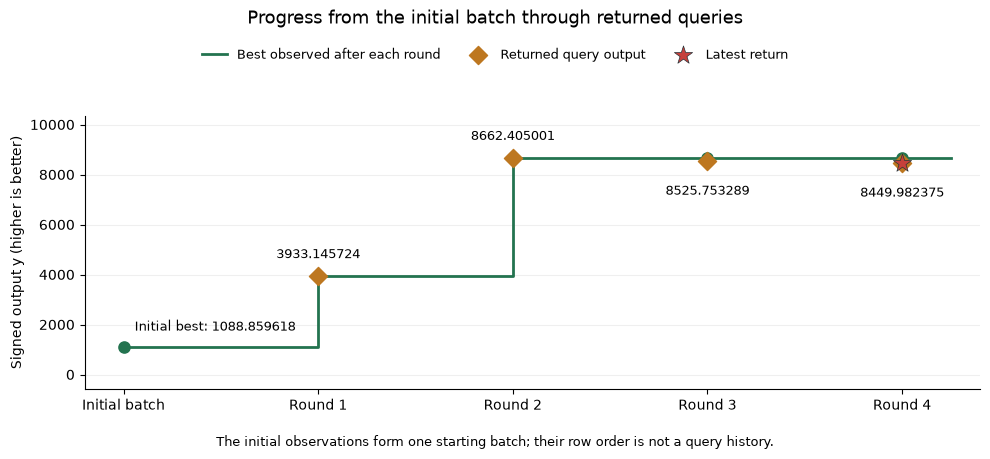

In [7]:
plot_round_progress(progress, save_to=figures / "observed-progress.png")

Rounds 1 and 2 improved the incumbent; rounds 3 and 4 did not. All four returns exceed the initial best. The latest return is lower than both rounds 2 and 3, despite all three inputs being near the upper boundary. Nearby high measurements do not establish a maximum or identify the effect of changing an individual coordinate.

The best observed output has changed from **1088.859618** in the initial batch to **8662.405001**, a total gain of **7573.545383 output units**. The latest return minus the previous best is **-212.422627**.

## 4. Examine the strongest input combinations

Keep all four coordinates visible together. This table and input-profile figure
show the five strongest measured combinations, with their actual outputs beside
them. Input settings share a fixed 0–1 colour scale; the colours do not represent
performance or fitted input effects.

The figure rounds input labels to three decimals; use the table for six-decimal settings.

In [8]:
ranked = data.assign(rank=data["y"].rank(ascending=False, method="min").astype(int))
strongest = ranked.sort_values(["rank", "observation_id"]).head(5)
display(strongest[["rank", "observation_id", "source_round", *input_columns, "y"]]
        .set_index("observation_id")
        .style.format({column: "{:.6f}" for column in [*input_columns, "y"]}))

,rank,source_round,x1,x2,x3,x4,y
observation_id,,,,,,,
round-02,1,2,0.999999,0.999999,0.999999,0.999999,8662.405001
round-03,2,3,0.996065,0.996814,0.999999,0.999999,8525.753289
round-04,3,4,0.999515,0.989282,0.999999,0.999999,8449.982375
round-01,4,1,0.375048,0.953644,0.999999,0.999999,3933.145724
initial-016,5,0,0.224189,0.846480,0.879484,0.878516,1088.859618


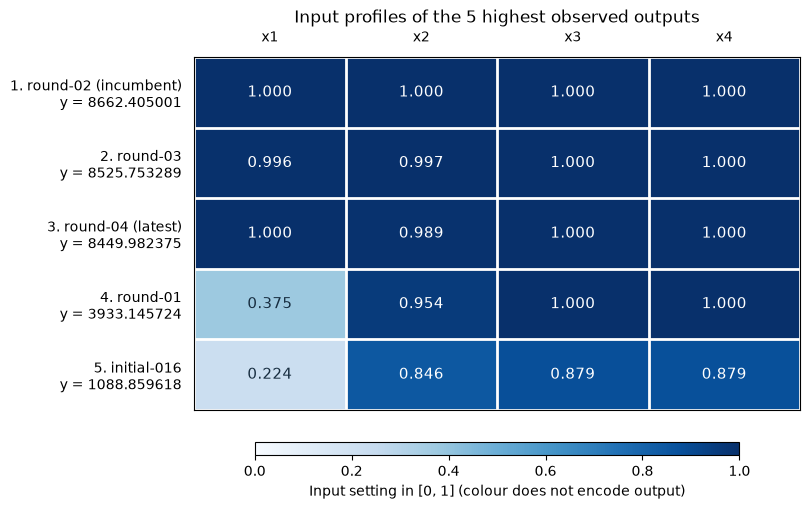

In [9]:
plot_input_profiles(
    strongest,
    input_columns=input_columns,
    latest_id=latest["observation_id"],
    incumbent_id=incumbent["observation_id"],
    save_to=figures / "strongest-input-profiles.png",
)

The four returned queries all use **x3 = x4 = 0.999999** and exceed every initial output. Rounds 2, 3 and 4 are the three highest observations, with x1 and x2 near their upper limits. Round 4 is the lowest of those three. These are measured combinations worth examining; the sequence does not establish monotonic input effects or prove a boundary optimum.

### How close is the latest query to the previous best?

Proximity in a two-coordinate projection can conceal differences in the other
inputs. Compare the latest query with the incumbent available before its return,
using every coordinate. Each setting already uses the same 0–1 range, so ordinary
Euclidean distance gives a descriptive geometric comparison without fitting a model.

In [10]:
previous_best = earlier.loc[earlier["y"].idxmax()]
coordinate_change = latest[input_columns].astype(float) - previous_best[input_columns].astype(float)
display(pd.DataFrame({
    "Previous best": previous_best[input_columns].astype(float),
    "Latest query": latest[input_columns].astype(float),
    "Latest minus previous best": coordinate_change,
}).style.format(precision=6))

earlier_distances = np.linalg.norm(
    earlier[input_columns].to_numpy() - latest[input_columns].to_numpy(dtype=float),
    axis=1,
)
nearest_previous = earlier.iloc[earlier_distances.argmin()]
distance_to_previous_best = float(np.linalg.norm(coordinate_change.to_numpy()))
latest_output_change = float(latest["y"] - previous_best["y"])
print(f"Previous best: {previous_best['observation_id']}; y = {previous_best['y']:.6f}")
print(f"Full four-input distance to previous best: {distance_to_previous_best:.6f}")
print(f"Latest output minus previous best: {latest_output_change:+.6f}")
print(f"Nearest earlier observation: {nearest_previous['observation_id']} "
      f"(distance {earlier_distances.min():.6f})")
print(f"Repeated full input combinations: {int(data.duplicated(input_columns).sum())}")

,Previous best,Latest query,Latest minus previous best
x1,0.999999,0.999515,-0.000484
x2,0.999999,0.989282,-0.010717
x3,0.999999,0.999999,0.000000
x4,0.999999,0.999999,0.000000


Previous best: round-02; y = 8662.405001
Full four-input distance to previous best: 0.010728
Latest output minus previous best: -212.422627
Nearest earlier observation: round-03 (distance 0.008285)
Repeated full input combinations: 0


The previous best is **round-02**; its full 4-input distance from round 4 is **0.010728**. The nearest earlier observation is **round-03** (distance **0.008285**). The latest output is **212.422627 lower** than the previous best.

All coordinates share the same input range, but Euclidean distance does not account for different input relevance or predict an output change. Several settings changed together. No identical-input repeats are available to measure repeat-evaluation noise.

## 5. Carry the evidence into model review

The upper-boundary region still contains the strongest measured combinations. Two successive nearby returns have now fallen below the round 2 incumbent. Keep the substantial initial gain and these later non-improvements visible when reviewing the next proposal.

A subsequent Week 5 model study should compare held-out prediction errors with the mean baseline, inspect uncertainty and noise sensitivity, and review candidate selection with **nine query opportunities remaining**, including Week 5.

The [saved Week 4 model notebook](../Week_04/model_predictions.ipynb) is the historical source for the submitted query and forecast. This observation review does not refit it or select a new query. Week 4 evaluation is confirmed in the [submission log](../../../submissions/README.md).

**Historical forecast check:** the [saved Week 4 model run](../Week_04/model_predictions.ipynb) predicted **8484.768502** for the submitted input. The measured return was **8449.982375**, or **34.786127 lower**. The saved forecast is rounded to six decimals. This comparison uses a prediction made before its answer was known; a single forecast error does not establish calibration.